## EDA Project - SwiftCart Retail Analysis

### Sprint 1

In [1]:
## Importing libraries
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

In [2]:
import warnings 
warnings.filterwarnings('ignore')

In [3]:
# Loading the datasets
df_raw = pd.read_csv("SwiftCart_Store_Data_for_Students.csv")
df = df_raw.copy() 

## Basic Data Understanding

In [4]:
print("Dataset shape:")
print(df.shape)

Dataset shape:
(31047, 21)


In [5]:
print("Columns:")
print(df.columns.tolist())

Columns:
['index', 'Order ID', 'Cust ID', 'Gender', 'Age', 'Age Group', 'Date', 'Month', 'Status', 'Channel ', 'SKU', 'Category', 'Size', 'Qty', 'currency', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'ship-country', 'B2B']


In [6]:
print("Data types:")
df.dtypes

Data types:


index                object
Order ID             object
Cust ID              object
Gender               object
Age                  object
Age Group            object
Date                float64
Month                object
Status               object
Channel              object
SKU                  object
Category             object
Size                 object
Qty                   int64
currency             object
Amount                int64
ship-city            object
ship-state           object
ship-postal-code      int64
ship-country         object
B2B                    bool
dtype: object

In [7]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31047 entries, 0 to 31046
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   index             29967 non-null  object 
 1   Order ID          29967 non-null  object 
 2   Cust ID           29968 non-null  object 
 3   Gender            29972 non-null  object 
 4   Age               29962 non-null  object 
 5   Age Group         29979 non-null  object 
 6   Date              30582 non-null  float64
 7   Month             30582 non-null  object 
 8   Status            31047 non-null  object 
 9   Channel           31047 non-null  object 
 10  SKU               31047 non-null  object 
 11  Category          31047 non-null  object 
 12  Size              31047 non-null  object 
 13  Qty               31047 non-null  int64  
 14  currency          31047 non-null  object 
 15  Amount            31047 non-null  int64  
 16  ship-city         3

In [8]:
print("Summary Statistics:")
df.describe()

Summary Statistics:


,Date,Qty,Amount,ship-postal-code
count,30582.000000,31047.00000,31047.000000,3.104700e+04
mean,45119.190864,1.01195,682.074822,4.643526e+05
std,15106.052476,0.29197,268.582173,2.931307e+05
min,44565.000000,1.00000,229.000000,1.100010e+05
25%,44626.000000,1.00000,486.000000,3.130010e+05
50%,44718.000000,1.00000,646.000000,5.000280e+05
75%,44810.000000,1.00000,794.000000,6.000405e+05
max,849642.000000,20.00000,3036.000000,1.250070e+07


In [49]:
df.head()

,Order ID,Cust ID,Gender,Age,Age Group,Date,Month,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B
0,171-1029312-3038738,1029312.0,Women,37,Adult,2022-12-04,Dec,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1,INR,376.0,MOHALI,PUNJAB,140301,IN,False
1,405-2183842-2225946,2183842.0,Women,29,Adult,2022-12-04,Dec,Delivered,Ajio,SET414-KR-NP-L,Set,L,1,INR,1449.0,GURUGRAM,HARYANA,122002,IN,False
2,171-1641533-8921966,1641533.0,Women,67,Senior,2022-12-04,Dec,Delivered,Myntra,SET261-KR-PP-S,Set,S,1,INR,453.0,KOLKATA,WEST BENGAL,700029,IN,False
3,404-7490807-6300351,7490807.0,Women,20,Adult,2022-12-04,Dec,Delivered,Amazon,SET110-KR-PP-M,Set,M,1,INR,729.0,THANJAVUR,TAMIL NADU,613007,IN,False
4,403-9293516-4577154,9293516.0,Women,62,Senior,2022-12-04,Dec,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1,INR,544.0,GURUGRAM,HARYANA,122001,IN,False


In [10]:
print("Duplicate Values")
df.duplicated().sum()

Duplicate Values


np.int64(0)

In [11]:
print("Number of unique values:")
df.nunique()

Number of unique values:


index               29950
Order ID            27555
Cust ID             27493
Gender                  2
Age                    74
Age Group               3
Date                   43
Month                  12
Status                  4
Channel                 7
SKU                  5287
Category                8
Size                   11
Qty                    14
currency                1
Amount                769
ship-city            2603
ship-state             50
ship-postal-code     4959
ship-country            1
B2B                     2
dtype: int64

In [12]:
df.describe(include="object")

,index,Order ID,Cust ID,Gender,Age,Age Group,Month,Status,Channel,SKU,Category,Size,currency,ship-city,ship-state,ship-country
count,29967,29967,29968,29972,29962,29979,30582,31047,31047,31047,31047,31047,31047,31047,31047,31047
unique,29950,27555,27493,2,74,3,12,4,7,5287,8,11,1,2603,50,1
top,155290.0,403-4984515-8861958,4984515.0,Women,28.0,Adult,Mar,Delivered,Amazon,JNE3797-KR-L,Set,M,INR,BENGALURU,MAHARASHTRA,IN
freq,8,12,12,20813,804,15030,2793,28641,11016,273,12391,5485,31047,2540,4519,31047


In [13]:
## Removing extra spaces from columns
df.columns = df.columns.str.strip()

In [14]:
## Checking missing values
df.isnull().sum()

index               1080
Order ID            1080
Cust ID             1079
Gender              1075
Age                 1085
Age Group           1068
Date                 465
Month                465
Status                 0
Channel                0
SKU                    0
Category               0
Size                   0
Qty                    0
currency               0
Amount                 0
ship-city              0
ship-state             0
ship-postal-code       0
ship-country           0
B2B                    0
dtype: int64

In [15]:
## Missing Values
missing = df.isnull().sum()
print(missing[missing > 0])

index        1080
Order ID     1080
Cust ID      1079
Gender       1075
Age          1085
Age Group    1068
Date          465
Month         465
dtype: int64


#### Converting To Valid DataTypes

In [16]:
## Prepare Date and Month columns
df["Date"] = pd.to_datetime(
    df["Date"],
    unit="D",
    origin="1899-12-30",
    errors="coerce"
)
df["Month"] = df["Date"].dt.strftime("%b")

In [17]:
df["Amount"] = df["Amount"].astype(float)

In [18]:
df["Age"] = pd.to_numeric(df["Age"], errors="coerce").astype("Int64")

In [19]:
df["ship-postal-code"] = df["ship-postal-code"].astype("object")

In [21]:
## Droped these column as it just contains serial number and since pandas has it own row index it feels unnecessary
df.drop("index", axis=1, inplace=True)

In [23]:
print(df["Gender"].unique())
print(df["Status"].unique())
print(df["Category"].unique())
print(df["Channel"].unique())
print(df["Size"].unique())
print(df["Age Group"].unique())
print(df["ship-state"].unique())
print(df["ship-country"].unique())
print(df["B2B"].unique())

['Women' 'Men' nan]
['Delivered' 'Refunded' 'Cancelled' 'Returned']
['kurta' 'Set' 'Western Dress' 'Top' 'Saree' 'Blouse' 'Ethnic Dress'
 'Bottom']
['Myntra' 'Ajio' 'Amazon' 'Flipkart' 'Meesho' 'Others' 'Nalli']
['XXL' 'L' 'S' 'M' 'XL' 'XS' '3XL' 'Free' '6XL' '4XL' '5XL']
['Adult' 'Teenager' 'Senior' nan]
['PUNJAB' 'HARYANA' 'WEST BENGAL' 'TAMIL NADU' 'MAHARASHTRA' 'KARNATAKA'
 'ANDHRA PRADESH' 'KERALA' 'ASSAM' 'TELANGANA' 'DELHI' 'ODISHA'
 'RAJASTHAN' 'UTTAR PRADESH' 'MADHYA PRADESH' 'UTTARAKHAND'
 'ANDAMAN & NICOBAR ' 'GUJARAT' 'CHANDIGARH' 'JHARKHAND' 'BIHAR'
 'HIMACHAL PRADESH' 'PUDUCHERRY' 'DADRA AND NAGAR' 'SIKKIM' 'GOA'
 'ARUNACHAL PRADESH' 'MANIPUR' 'JAMMU & KASHMIR' 'TRIPURA' 'New Delhi'
 'CHHATTISGARH' 'Bihar' 'LADAKH' 'MEGHALAYA' 'NAGALAND' 'MIZORAM' 'goa'
 'Punjab' 'Delhi' 'Nagaland' 'delhi' 'Goa' 'Chandigarh' 'punjab'
 'Arunachal Pradesh' 'bihar' 'Manipur' 'Sikkim' 'Arunachal pradesh']
['IN']
[False  True]


In [24]:
# Standardize ship-state
df["ship-state"] = df["ship-state"].str.strip().str.upper()
df["ship-state"] = df["ship-state"].replace("NEW DELHI", "DELHI")

## Handling Missing Values

In [25]:
print(df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nAge data type:", df["Age"].dtype)
print("Date data type:", df["Date"].dtype)

(31047, 20)

Missing values:
Order ID            1080
Cust ID             1079
Gender              1075
Age                 1091
Age Group           1068
Date                 488
Month                488
Status                 0
Channel                0
SKU                    0
Category               0
Size                   0
Qty                    0
currency               0
Amount                 0
ship-city              0
ship-state             0
ship-postal-code       0
ship-country           0
B2B                    0
dtype: int64

Age data type: Int64
Date data type: datetime64[ns]


In [24]:
missing_percent = df.isnull().mean() * 100
print(missing_percent.round(2))

Order ID            3.48
Cust ID             3.48
Gender              3.46
Age                 3.51
Age Group           3.44
Date                1.57
Month               1.57
Status              0.00
Channel             0.00
SKU                 0.00
Category            0.00
Size                0.00
Qty                 0.00
currency            0.00
Amount              0.00
ship-city           0.00
ship-state          0.00
ship-postal-code    0.00
ship-country        0.00
B2B                 0.00
dtype: float64


In [26]:
# 10. Handle missing Gender
df["Gender"] = df["Gender"].fillna("Unknown")

In [27]:
## 11. Create Age Group from Age
def get_age_group(age):
    if pd.isna(age):
        return pd.NA
    elif age < 20:
        return "Teenager"
    elif age < 60:
        return "Adult"
    else:
        return "Senior"

df["Age Group"] = df["Age"].apply(get_age_group)

##### Identifying Outliers

In [28]:

for col in ["Age", "Qty", "Amount"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[
        df[col].notna() &
        ((df[col] < lower) | (df[col] > upper))
    ]
    print("\n", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print(col, ":", len(outliers))



 Age
Q1: 28
Q3: 47
IQR: 19
Lower limit: -0.5
Upper limit: 75.5
Age : 623

 Qty
Q1: 1.0
Q3: 1.0
IQR: 0.0
Lower limit: 1.0
Upper limit: 1.0
Qty : 171

 Amount
Q1: 486.0
Q3: 794.0
IQR: 308.0
Lower limit: 24.0
Upper limit: 1256.0
Amount : 1115


In [29]:
df['Qty'].value_counts().sort_index()

Qty
1     30876
2       130
3        19
4         6
5         1
8         3
10        1
11        1
12        1
13        3
15        3
17        1
18        1
20        1
Name: count, dtype: int64

##### Analyzing & Removing Invalid Age

In [30]:
df[df['Age'] > 75]['Age'].value_counts().sort_index()

Age
76     187
77     202
78     211
296      1
333      1
370     10
407      1
444      1
481      1
518      1
592      3
666      1
740      3
Name: count, dtype: Int64

In [31]:
df = df[df['Age'].isna() | (df['Age'] <= 100)]

In [32]:
(df['Age'] > 100).sum()

np.int64(0)

In [34]:
# 15. Check remaining records
print("Original rows:", len(df_raw))
print("Remaining rows:", len(df))

Original rows: 31047
Remaining rows: 31024


In [35]:
## Handling Missing Age
df['Age'] = df['Age'].fillna(df['Age'].median())

In [36]:
## Creating Age Group with help of Age
df["Age Group"] = df["Age"].apply(get_age_group)

In [37]:
df[df['Order ID'].isna() & df['Cust ID'].isna()].shape

(41, 20)

In [50]:
## Recover missing Customer IDs
extracted_id = df['Order ID'].str.split('-').str[1]

cust_id = pd.to_numeric(df['Cust ID'], errors='coerce').astype('Int64')

match = extracted_id == cust_id.astype('string')

print("Matching IDs:", match.sum())

Matching IDs: 26677


In [51]:
print("Total rows:", len(df))
print("Matching rows:", match.sum())
print("Match percentage:", round(match.mean() * 100, 2), "%")

Total rows: 31024
Matching rows: 26677
Match percentage: 89.1 %


In [52]:
df.loc[
    ~match & df['Order ID'].notna() & df['Cust ID'].notna(),
    ['Order ID', 'Cust ID']
].head(10)

,Order ID,Cust ID
12,408-0265357-4939534,265357.0
14,407-0442660-2736366,442660.0
19,406-0244536-2177175,244536.0
22,403-0950590-5005155,950590.0
24,402-0398999-0011565,398999.0
27,406-0986513-0498758,986513.0
28,406-0947452-6044339,947452.0
40,402-0637532-2672317,637532.0
41,402-0637532-2672317,637532.0
52,403-0817885-3061963,817885.0


In [53]:
df[['Order ID', 'Cust ID']].head(10)

,Order ID,Cust ID
0,171-1029312-3038738,1029312.0
1,405-2183842-2225946,2183842.0
2,171-1641533-8921966,1641533.0
3,404-7490807-6300351,7490807.0
4,403-9293516-4577154,9293516.0
5,407-1298130-0368305,1298130.0
6,407-1298130-0368305,1298130.0
7,171-5561216-3398711,5561216.0
8,408-2935263-2935550,2935263.0
9,404-2648970-9042715,2648970.0


In [54]:
extracted_id = pd.to_numeric(
    df['Order ID'].str.split('-').str[1],
    errors='coerce'
)

df['Cust ID'] = df['Cust ID'].fillna(extracted_id)

In [55]:
print("Missing Cust ID:", df['Cust ID'].isna().sum())

Missing Cust ID: 41


In [56]:
df.isnull().sum()

Order ID            1078
Cust ID               41
Gender                 0
Age                    0
Age Group              0
Date                 488
Month                488
Status                 0
Channel                0
SKU                    0
Category               0
Size                   0
Qty                    0
currency               0
Amount                 0
ship-city              0
ship-state             0
ship-postal-code       0
ship-country           0
B2B                    0
dtype: int64

In [57]:
print("Earliest date:", df['Date'].min())
print("Latest date:", df['Date'].max())

Earliest date: 2022-01-04 00:00:00
Latest date: 2022-12-06 00:00:00


In [58]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [59]:
df[['Age', 'Qty', 'Amount']].describe()

,Age,Qty,Amount
count,31024.0,31024.000000,31024.000000
mean,39.394759,1.011958,682.162261
std,14.849749,0.292078,268.599470
min,18.0,1.000000,229.000000
25%,28.0,1.000000,486.000000
50%,37.0,1.000000,646.000000
75%,47.0,1.000000,794.000000
max,78.0,20.000000,3036.000000


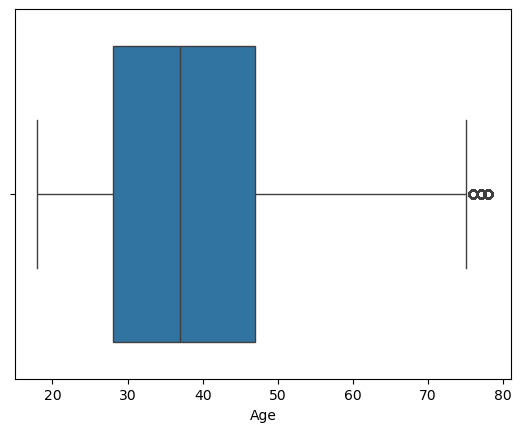

In [68]:
sns.boxplot(x=df["Age"])
plt.show()

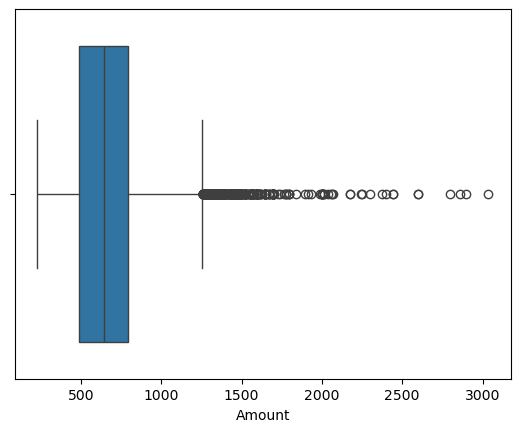

In [69]:
sns.boxplot(x=df["Amount"])
plt.show()

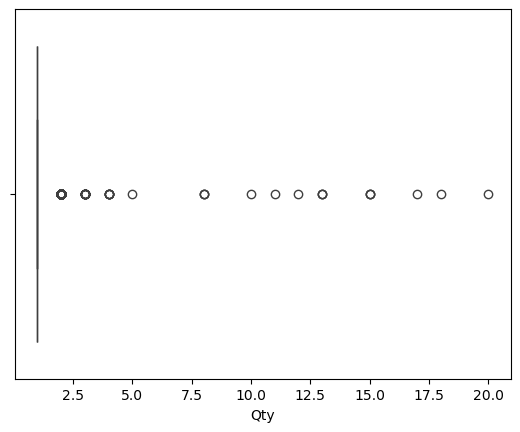

In [70]:
sns.boxplot(x=df["Qty"])
plt.show()

In [63]:
print(df['Gender'].value_counts())
print(df['Age Group'].value_counts())
print(df['Category'].value_counts())
print(df['Size'].value_counts())
print(df['Status'].value_counts())
print(df['Channel'].value_counts())

Gender
Women      20794
Men         9155
Unknown     1075
Name: count, dtype: int64
Age Group
Adult       25801
Senior       3812
Teenager     1411
Name: count, dtype: int64
Category
Set              12384
kurta            10433
Western Dress     4065
Top               2191
Saree             1380
Ethnic Dress       264
Blouse             229
Bottom              78
Name: count, dtype: int64
Size
M       5481
L       5138
XL      4434
S       4173
XXL     4064
3XL     3345
XS      2499
Free    1408
6XL      208
5XL      161
4XL      113
Name: count, dtype: int64
Status
Delivered    28618
Returned      1045
Cancelled      844
Refunded       517
Name: count, dtype: int64
Channel
Amazon      11007
Myntra       7247
Flipkart     6700
Ajio         1930
Nalli        1482
Meesho       1398
Others       1260
Name: count, dtype: int64


In [62]:
print("Average sales amount:", df['Amount'].mean())
print("Median sales amount:", df['Amount'].median())

Average sales amount: 682.1622614749871
Median sales amount: 646.0


In [64]:
print("Final shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nAge range:", df['Age'].min(), df['Age'].max())
print("Quantity range:", df['Qty'].min(), df['Qty'].max())
print("Amount range:", df['Amount'].min(), df['Amount'].max())

Final shape: (31024, 20)

Missing values:
Order ID            1078
Cust ID               41
Gender                 0
Age                    0
Age Group              0
Date                 488
Month                488
Status                 0
Channel                0
SKU                    0
Category               0
Size                   0
Qty                    0
currency               0
Amount                 0
ship-city              0
ship-state             0
ship-postal-code       0
ship-country           0
B2B                    0
dtype: int64

Exact duplicate rows: 0

Data types:
Order ID                    object
Cust ID                     object
Gender                      object
Age                          Int64
Age Group                   object
Date                datetime64[ns]
Month                       object
Status                      object
Channel                     object
SKU                         object
Category                    object
Size                  

In [65]:
df.to_csv('swiftcart_cleaned.csv', index=False)

## Sprint 1 – Data Quality Summary

* **Missing values:** Gender, Age, and Age Group were handled using the documented cleaning rules. Missing Order IDs, Customer IDs, and Dates were retained when they could not be reliably recovered.
* **Date preparation:** Date was converted to datetime format, and Month was derived from Date. Missing dates were not guessed.
* **Duplicate analysis:** No exact duplicate rows were found. Repeated Order IDs were retained because they may represent multiple products within an order.
* **Outlier analysis:** Potential outliers in Age, Qty, and Amount were investigated. Valid observations were retained rather than removed solely because of statistical thresholds.
* **Categorical consistency:** Text columns were checked for whitespace and category inconsistencies.
* **Final validation:** Data types, missing values, duplicates, ranges, and date values were reviewed.
* **Output:** The cleaned dataset was saved as `swiftcart_cleaned.csv` for subsequent analysis.
